# Домашние задание

1. Добавить Bias и посчитать для них градиенты.
2. Сравнить градинеты с тем, как считает PyTorch AutoGrad.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cpu")
dtype = torch.float

In [3]:
INPUT_SIZE = 1
HIDDEN_SIZE = 10
OUTPUT_SIZE = 1

In [4]:
# Create random input and output data
x = np.arange(-10, 10, 0.1).reshape(-1, 1)
y = x**2 * np.sin(x).reshape(-1, 1)

x = torch.FloatTensor(x)
y = torch.FloatTensor(y)

# Randomly initialize weights
w1 = torch.randn(INPUT_SIZE, HIDDEN_SIZE, device=device, dtype=dtype)
w2 = torch.randn(HIDDEN_SIZE, OUTPUT_SIZE, device=device, dtype=dtype)

b1 = torch.zeros(HIDDEN_SIZE)
b2 = torch.zeros(OUTPUT_SIZE)

In [5]:
learning_rate = 1e-4
for t in range(50_000):
    # Forward pass: compute predicted y
    h1 = x @ w1 + b1
    h1_relu = h1.relu()
    y_pred = h1_relu @ w2 + b2

    loss = (y_pred - y).pow(2).mean().item()
    if t % 1000 == 0:
        print(t, loss)

    # Backward pass
    # 1) dL/dy_pred
    dL_dy_pred = 2 * (y_pred - y) / y.numel()
    # 2) слой w2
    grad_w2 = h1_relu.T @ dL_dy_pred
    grad_b2 = dL_dy_pred.sum(dim=0)
    dL_dh1_relu = dL_dy_pred @ w2.T
    # 3) ReLU
    dL_dh1 = dL_dh1_relu * (h1 > 0).float()
    # 4) слой w1
    grad_w1 = x.T @ dL_dh1
    grad_b1 = dL_dh1.sum(dim=0)

    # Update weights using gradient descent
    w1 -= learning_rate * grad_w1
    b1 -= learning_rate * grad_b1
    w2 -= learning_rate * grad_w2
    b2 -= learning_rate * grad_b2

0 1307.510986328125
1000 638.958740234375
2000 636.157958984375
3000 632.9586181640625
4000 629.0858764648438
5000 624.22216796875
6000 617.80810546875
7000 610.2572021484375
8000 601.2958984375
9000 589.771240234375
10000 579.8324584960938
11000 572.5133666992188
12000 567.5248413085938
13000 564.1996459960938
14000 561.8713989257812
15000 559.694580078125
16000 558.5758056640625
17000 557.78564453125
18000 557.1986694335938
19000 556.7444458007812
20000 556.375244140625
21000 556.0756225585938
22000 555.8251342773438
23000 555.60986328125
24000 555.4229125976562
25000 555.2581176757812
26000 555.111083984375
27000 554.97998046875
28000 554.8616943359375
29000 554.75341796875
30000 554.6539306640625
31000 554.56201171875
32000 554.4752197265625
33000 554.3931884765625
34000 554.3150634765625
35000 554.2400512695312
36000 554.1669921875
37000 554.09619140625
38000 554.0266723632812
39000 553.9578857421875
40000 553.8894653320312
41000 553.821533203125
42000 553.7537841796875
43000 553.

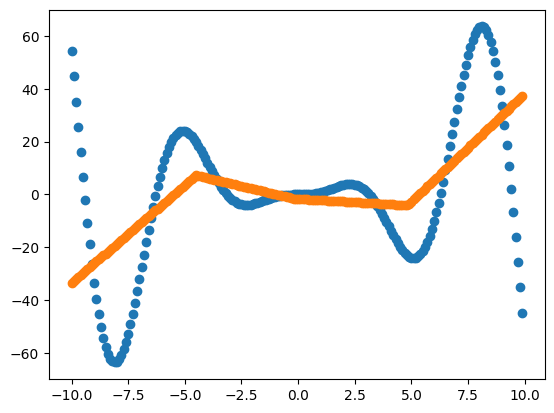

In [6]:
plt.scatter(x, y)
plt.scatter(x, y_pred)

---

In [7]:
from torch import nn


class TwoLayerNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        """
        TwoLayerNet наследуется от nn.Module и тем самым полчаем возможность
        переопределять методы класса.
        В конструктуре создаем слои (обучаемые веса) и другие нужные перменные/функции,
        которые нужны для модели
        """
        super(TwoLayerNet, self).__init__()
        self.linear1 = torch.nn.Linear(input_size, hidden_size, bias=True)
        self.linear2 = torch.nn.Linear(hidden_size, output_size, bias=True)

    def forward(self, x):
        """
        Метод forward отвечает за прямое распростронение модели,
        поэтому данный метод нужно переопределять обязательно,
        чтобы задать логику прямого распростронения.
        Именно в этот момент начинает строится динамический граф
        """
        h_relu = torch.relu(self.linear1(x))
        y_pred = self.linear2(h_relu)

        return y_pred

In [8]:
model = TwoLayerNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)

loss_fn = torch.nn.MSELoss(reduction="mean")
optimizer = torch.optim.SGD(model.parameters(), lr=1e-4)

for t in range(50_000):
    y_pred = model(x)

    loss = loss_fn(y_pred, y)
    if t % 1000 == 0:
        print(t, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 765.3448486328125
1000 638.4346923828125
2000 634.962646484375
3000 630.9310302734375
4000 625.971435546875
5000 619.6090698242188
6000 611.5197143554688
7000 602.4403686523438
8000 593.1906127929688
9000 584.8600463867188
10000 577.5736083984375
11000 571.1634521484375
12000 565.611083984375
13000 561.3963012695312
14000 557.81201171875
15000 555.352783203125
16000 553.7932739257812
17000 552.7157592773438
18000 552.01171875
19000 551.5132446289062
20000 551.1381225585938
21000 550.8432006835938
22000 550.614501953125
23000 550.418212890625
24000 550.2361450195312
25000 550.06298828125
26000 549.8934936523438
27000 549.7256469726562
28000 549.5548095703125
29000 549.3787841796875
30000 549.2005615234375
31000 549.0175170898438
32000 548.8287353515625
33000 548.630859375
34000 548.4277954101562
35000 548.2199096679688
36000 548.0079345703125
37000 547.7886352539062
38000 547.56494140625
39000 547.3410034179688
40000 547.1133422851562
41000 546.8786010742188
42000 546.6431274414062
43

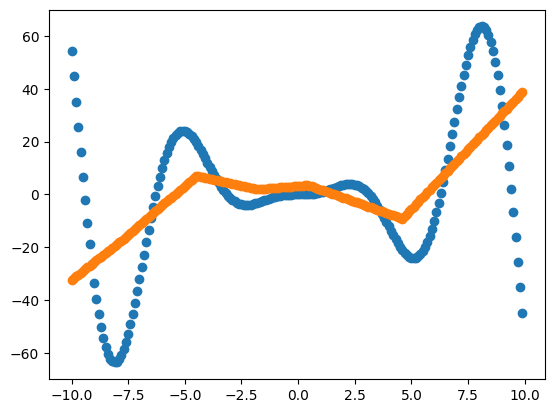

In [9]:
plt.scatter(x, y)
plt.scatter(x, y_pred.detach().numpy())